# Three Principles, One Neural Representation

This notebook fixes the PDE, the trial space, and the optimizer.
Only the optimality principle changes.
The problem is the Poisson equation
$-u''(x)=\pi^2\sin(\pi x)$ on $[0,1]$ with $u(0)=u(1)=0$.

The three losses are the strong form, the weak form, and the energy functional.
This is the cleanest way to see what each principle asks of the same network.


In [1]:
from pathlib import Path

# Paths are relative to the folder that holds this notebook.
ROOT = Path.cwd()
LOCAL_FIG_DIR = ROOT / "figs"
CHAPTER_FIG_DIR = LOCAL_FIG_DIR


from pathlib import Path

import matplotlib


import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm


STYLE_PATH = ROOT / "sciml_style.mplstyle"  # optional; the book style needs a LaTeX install

if STYLE_PATH.exists():
    plt.style.use(STYLE_PATH)

torch.manual_seed(42)
np.random.seed(42)


def exact_solution(x: np.ndarray) -> np.ndarray:
    return np.sin(np.pi * x)


def exact_derivative(x: np.ndarray) -> np.ndarray:
    return np.pi * np.cos(np.pi * x)


def source_term(x: torch.Tensor) -> torch.Tensor:
    return np.pi**2 * torch.sin(np.pi * x)


class RawNetwork(nn.Module):
    def __init__(self, activation: type[nn.Module] = nn.Tanh) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            activation(),
            nn.Linear(32, 32),
            activation(),
            nn.Linear(32, 32),
            activation(),
            nn.Linear(32, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class StrongBCModel(nn.Module):
    def __init__(self, activation: type[nn.Module] = nn.Tanh) -> None:
        super().__init__()
        self.nn = RawNetwork(activation)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * (1.0 - x) * self.nn(x)


def gauss_legendre(n: int = 64) -> tuple[torch.Tensor, torch.Tensor]:
    nodes, weights = np.polynomial.legendre.leggauss(n)
    nodes = 0.5 * (nodes + 1.0)
    weights = 0.5 * weights
    x = torch.tensor(nodes, dtype=torch.float32).reshape(-1, 1)
    w = torch.tensor(weights, dtype=torch.float32).reshape(-1, 1)
    return x, w


X_QUAD, W_QUAD = gauss_legendre(64)
X_COLLOC = torch.linspace(0.01, 0.99, 64, dtype=torch.float32).reshape(-1, 1)
X_EVAL_NP = np.linspace(0.0, 1.0, 500)
N_ADAM = 4000
N_LBFGS = 80
COLORS = {
    "PINN (strong form)": "tab:blue",
    "VPINN (weak form)": "tab:orange",
    "Deep Ritz (energy)": "tab:green",
}


def compute_derivatives(
    model: nn.Module,
    x: torch.Tensor,
    order: int = 2,
) -> tuple[torch.Tensor, ...]:
    x_local = x.clone().detach().requires_grad_(True)
    u = model(x_local)
    du = torch.autograd.grad(
        u,
        x_local,
        grad_outputs=torch.ones_like(u),
        create_graph=True,
    )[0]
    if order >= 2:
        d2u = torch.autograd.grad(
            du,
            x_local,
            grad_outputs=torch.ones_like(du),
            create_graph=True,
        )[0]
        return u, du, d2u
    return u, du


def evaluate_model(model: nn.Module, x_np: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    x_t = torch.tensor(x_np, dtype=torch.float32).reshape(-1, 1)
    x_t = x_t.requires_grad_(True)
    u = model(x_t)
    du = torch.autograd.grad(
        u,
        x_t,
        grad_outputs=torch.ones_like(u),
        create_graph=False,
    )[0]
    return u.detach().numpy().ravel(), du.detach().numpy().ravel()


def relative_l2_error(prediction: np.ndarray, truth: np.ndarray) -> float:
    numerator = np.sqrt(np.mean((prediction - truth) ** 2))
    denominator = np.sqrt(np.mean(truth**2))
    return float(numerator / denominator)


def train_strong_form() -> tuple[nn.Module, list[float]]:
    torch.manual_seed(42)
    model = StrongBCModel()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history: list[float] = []

    for _ in tqdm(range(N_ADAM), desc="PINN strong"):
        optimizer.zero_grad()
        _, _, d2u = compute_derivatives(model, X_COLLOC)
        loss = torch.mean((-d2u - source_term(X_COLLOC)) ** 2)
        loss.backward()
        optimizer.step()
        history.append(float(loss.item()))

    optimizer_lbfgs = optim.LBFGS(
        model.parameters(),
        lr=0.5,
        max_iter=20,
        history_size=50,
    )
    for _ in tqdm(range(N_LBFGS), desc="PINN strong L-BFGS"):
        def closure() -> torch.Tensor:
            optimizer_lbfgs.zero_grad()
            _, _, d2u = compute_derivatives(model, X_COLLOC)
            loss = torch.mean((-d2u - source_term(X_COLLOC)) ** 2)
            loss.backward()
            history.append(float(loss.item()))
            return loss

        optimizer_lbfgs.step(closure)

    return model, history


def train_weak_form(num_test_functions: int = 10) -> tuple[nn.Module, list[float]]:
    torch.manual_seed(42)
    model = StrongBCModel()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history: list[float] = []

    ks = torch.arange(1, num_test_functions + 1, dtype=torch.float32).reshape(1, -1)
    rhs = (W_QUAD * source_term(X_QUAD) * torch.sin(ks * np.pi * X_QUAD)).sum(dim=0)

    for _ in tqdm(range(N_ADAM), desc="VPINN weak"):
        optimizer.zero_grad()
        _, du = compute_derivatives(model, X_QUAD, order=1)
        dv = ks * np.pi * torch.cos(ks * np.pi * X_QUAD)
        lhs = (W_QUAD * du * dv).sum(dim=0)
        loss = torch.sum((lhs - rhs) ** 2)
        loss.backward()
        optimizer.step()
        history.append(float(loss.item()))

    optimizer_lbfgs = optim.LBFGS(
        model.parameters(),
        lr=0.5,
        max_iter=20,
        history_size=50,
    )
    for _ in tqdm(range(N_LBFGS), desc="VPINN weak L-BFGS"):
        def closure() -> torch.Tensor:
            optimizer_lbfgs.zero_grad()
            _, du = compute_derivatives(model, X_QUAD, order=1)
            dv = ks * np.pi * torch.cos(ks * np.pi * X_QUAD)
            lhs = (W_QUAD * du * dv).sum(dim=0)
            loss = torch.sum((lhs - rhs) ** 2)
            loss.backward()
            history.append(float(loss.item()))
            return loss

        optimizer_lbfgs.step(closure)

    return model, history


def train_deep_ritz() -> tuple[nn.Module, list[float]]:
    torch.manual_seed(42)
    model = StrongBCModel()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history: list[float] = []

    f_quad = source_term(X_QUAD)
    for _ in tqdm(range(N_ADAM), desc="Deep Ritz"):
        optimizer.zero_grad()
        u, du = compute_derivatives(model, X_QUAD, order=1)
        energy = 0.5 * (W_QUAD * du**2).sum() - (W_QUAD * f_quad * u).sum()
        energy.backward()
        optimizer.step()
        history.append(float(energy.item()))

    optimizer_lbfgs = optim.LBFGS(
        model.parameters(),
        lr=0.5,
        max_iter=20,
        history_size=50,
    )
    for _ in tqdm(range(N_LBFGS), desc="Deep Ritz L-BFGS"):
        def closure() -> torch.Tensor:
            optimizer_lbfgs.zero_grad()
            u, du = compute_derivatives(model, X_QUAD, order=1)
            energy = 0.5 * (W_QUAD * du**2).sum() - (W_QUAD * f_quad * u).sum()
            energy.backward()
            history.append(float(energy.item()))
            return energy

        optimizer_lbfgs.step(closure)

    return model, history


def save_figure(fig: plt.Figure, basename: str) -> None:
    LOCAL_FIG_DIR.mkdir(parents=True, exist_ok=True)
    CHAPTER_FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(LOCAL_FIG_DIR / f"{basename}.png", dpi=220, bbox_inches="tight")
    fig.savefig(LOCAL_FIG_DIR / f"{basename}.pdf", bbox_inches="tight")
    fig.savefig(CHAPTER_FIG_DIR / f"{basename}.png", dpi=220, bbox_inches="tight")
    fig.savefig(CHAPTER_FIG_DIR / f"{basename}.pdf", bbox_inches="tight")


## Train the three models

All three runs use the same strong Dirichlet trial space.
The only difference is the loss.


In [2]:
model_strong, history_strong = train_strong_form()
model_weak, history_weak = train_weak_form()
model_energy, history_energy = train_deep_ritz()


PINN strong:   0%|          | 0/4000 [00:00<?, ?it/s]

PINN strong:   3%|▎         | 118/4000 [00:00<00:03, 1174.41it/s]

PINN strong:   7%|▋         | 287/4000 [00:00<00:02, 1471.48it/s]

PINN strong:  11%|█▏        | 456/4000 [00:00<00:02, 1570.08it/s]

PINN strong:  16%|█▌        | 625/4000 [00:00<00:02, 1616.05it/s]

...

Deep Ritz:  92%|█████████▏| 3689/4000 [00:01<00:00, 2810.55it/s]

Deep Ritz:  99%|█████████▉| 3973/4000 [00:01<00:00, 2816.54it/s]

Deep Ritz: 100%|██████████| 4000/4000 [00:01<00:00, 2822.26it/s]

Deep Ritz L-BFGS:   0%|          | 0/80 [00:00<?, ?it/s]

Deep Ritz L-BFGS: 100%|██████████| 80/80 [00:00<00:00, 1426.97it/s]

## Compare the solutions, derivative errors, and optimization histories

The left panel shows the recovered solution.
The middle panel shows derivative error.
The right panel shows the optimizer history under the shared Adam and L-BFGS schedule.



Relative L2 errors
PINN (strong form)      u: 1.076e-06  du: 8.593e-06
VPINN (weak form)       u: 5.551e-06  du: 6.707e-05
Deep Ritz (energy)      u: 1.124e-05  du: 1.019e-04


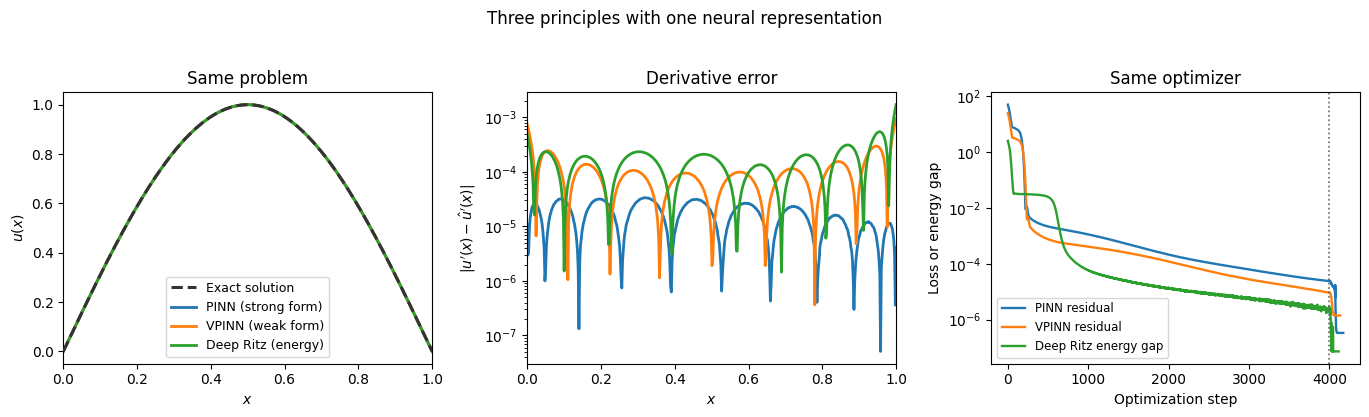

In [3]:
u_exact = exact_solution(X_EVAL_NP)
du_exact = exact_derivative(X_EVAL_NP)

results = {
    "PINN (strong form)": evaluate_model(model_strong, X_EVAL_NP),
    "VPINN (weak form)": evaluate_model(model_weak, X_EVAL_NP),
    "Deep Ritz (energy)": evaluate_model(model_energy, X_EVAL_NP),
}

fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.0))

axes[0].plot(
    X_EVAL_NP,
    u_exact,
    color="#333333",
    linestyle="--",
    linewidth=2.2,
    label="Exact solution",
    zorder=5,
)
for name, (u_pred, _) in results.items():
    axes[0].plot(
        X_EVAL_NP,
        u_pred,
        color=COLORS[name],
        linewidth=2.0,
        label=name,
    )
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel(r"$u(x)$")
axes[0].set_title("Same problem")
axes[0].set_xlim(0.0, 1.0)
axes[0].legend(loc="lower center", fontsize=9, frameon=True)

for name, (_, du_pred) in results.items():
    axes[1].semilogy(
        X_EVAL_NP,
        np.abs(du_pred - du_exact) + 1e-14,
        color=COLORS[name],
        linewidth=2.0,
    )
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel(r"$|u'(x) - \hat{u}'(x)|$")
axes[1].set_title("Derivative error")
axes[1].set_xlim(0.0, 1.0)

exact_energy = -np.pi**2 / 4.0
axes[2].semilogy(
    history_strong,
    color=COLORS["PINN (strong form)"],
    linewidth=1.7,
    label="PINN residual",
)
axes[2].semilogy(
    history_weak,
    color=COLORS["VPINN (weak form)"],
    linewidth=1.7,
    label="VPINN residual",
)
axes[2].semilogy(
    np.abs(np.asarray(history_energy) - exact_energy) + 1e-16,
    color=COLORS["Deep Ritz (energy)"],
    linewidth=1.7,
    label="Deep Ritz energy gap",
)
axes[2].axvline(N_ADAM, color="0.4", linestyle=":", linewidth=1.2)
axes[2].set_xlabel("Optimization step")
axes[2].set_ylabel("Loss or energy gap")
axes[2].set_title("Same optimizer")
axes[2].legend(fontsize=8.5, frameon=True)

fig.suptitle("Three principles with one neural representation", y=1.03)
fig.tight_layout()
fig

print("\nRelative L2 errors")
for name, (u_pred, du_pred) in results.items():
    u_err = relative_l2_error(u_pred, u_exact)
    du_err = relative_l2_error(du_pred, du_exact)
    print(f"{name:22s}  u: {u_err:.3e}  du: {du_err:.3e}")
